# Prueba de ida y vuelta por planos (sin modelo)

**Pregunta que responde:** si cortamos las etiquetas reales por un plano (axial, coronal o sagital), las llevamos a 256×256 (remuestreo + letterbox), las devolvemos a su geometría original y las reapilamos en un volumen, ¿cuánto se parece el resultado al volumen original?

Sirve para:
1. **Conocer los datos:** espaciado real en x, y, z de los 100 casos, orientación y si imagen y etiqueta comparten cabecera.
2. **Detectar errores de geometría** (ejes, desplazamientos, redondeos) antes de gastar horas de entrenamiento.
3. **Cuantificar lo que se pierde** al trabajar a 256×256 (fragmentos pequeños, error de posición en mm).

**Qué NO prueba:** que el espaciado físico esté bien interpretado (la ida y la vuelta usan el mismo número, así que un espaciado equivocado se cancelaría). Eso se comprueba con la auditoría de cabeceras y con la figura de los tres planos (la proporción debe verse anatómicamente razonable).

**Cómo se mide la referencia:** el plano **axial** reproduce la tubería actual (solo letterbox, sin remuestreo). Coronal y sagital se comparan contra él: no deberían ser mucho peores.

In [1]:
import ast
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import SimpleITK as sitk
from PIL import Image

# Raiz del repositorio: funciona si el kernel arranca en notebooks/ o en la raiz.
BASE_DIR = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "requirements.txt").is_file())
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))  # modulos .py del proyecto (p. ej. distancias_fragmentos)

ROOT = BASE_DIR                        # las celdas siguientes usan ROOT
NOTEBOOKS_DIR = BASE_DIR / "notebooks"
(BASE_DIR / "evidencias").mkdir(exist_ok=True)
OUT_SIZE = 256

# Funcion -> notebook donde vive ahora
SOURCES = {
    "resolve_repo_path":            "Ventaneo_hu.ipynb",
    "load_mha":                     "Ventaneo_hu.ipynb",
    "apply_hu_window":              "Ventaneo_hu.ipynb",
    "letterbox_pair":               "Targets_deteccion.ipynb",
    "restore_letterbox_label_mask": "Segmentacion_instancias.ipynb",
}


def load_team_definitions(sources, notebooks_dir=NOTEBOOKS_DIR):
    """Carga cada funcion (por AST, sin ejecutar el resto de celdas) desde su notebook."""
    by_notebook = {}
    for name, nb_name in sources.items():
        by_notebook.setdefault(nb_name, set()).add(name)

    for nb_name, wanted in by_notebook.items():
        nb_path = notebooks_dir / nb_name
        if not nb_path.is_file():
            raise FileNotFoundError(f"No existe {nb_path}")
        notebook = json.loads(nb_path.read_text(encoding="utf-8"))
        found = {}
        for cell in notebook.get("cells", []):
            if cell.get("cell_type") != "code":
                continue
            source = "".join(cell.get("source", []))
            try:
                tree = ast.parse(source)
            except SyntaxError:
                continue
            for node in tree.body:
                if isinstance(node, (ast.FunctionDef, ast.ClassDef)) and node.name in wanted:
                    found[node.name] = ast.get_source_segment(source, node)   # la ultima definicion gana
        missing = wanted - set(found)
        if missing:
            raise RuntimeError(f"En {nb_name} no encuentro: {sorted(missing)}")
        exec("\n\n".join(found[n] for n in sorted(found)), globals())
        for n in sorted(found):
            print(f"  {n:30s} <- {nb_name}")


print("Funciones cargadas de los notebooks del equipo:")
load_team_definitions(SOURCES)

df = pd.read_csv(BASE_DIR / "splits" / "dataset.csv", dtype={"case_id": str})
print("Casos en dataset.csv:", len(df), "| columnas:", list(df.columns))

Funciones cargadas de los notebooks del equipo:
  apply_hu_window                <- Ventaneo_hu.ipynb
  load_mha                       <- Ventaneo_hu.ipynb
  resolve_repo_path              <- Ventaneo_hu.ipynb
  letterbox_pair                 <- Targets_deteccion.ipynb
  restore_letterbox_label_mask   <- Segmentacion_instancias.ipynb
Casos en dataset.csv: 100 | columnas: ['case_id', 'split', 'image_path', 'label_path', 'n_fragments', 'complexity']


## 1. Auditoría de cabeceras (los 100 casos, sin cargar píxeles)
Espaciado (x, y, z), tamaño, **dirección** (orientación de los ejes) y si la imagen y su etiqueta comparten cabecera. Un desajuste entre imagen y etiqueta sería una señal roja.

Combinaciones de espaciado (sx, sy, sz) en mm:


,sx,sy,sz,casos
22,0.78125,0.78125,1.00000,6
24,0.78200,0.78200,0.79895,5
26,0.78200,0.78200,0.80103,5
20,0.78125,0.78125,0.80000,3
15,0.77539,0.77539,1.00000,2
...,...,...,...,...
71,0.92969,0.92969,0.80000,1
73,0.94600,0.94600,0.79895,1
72,0.94141,0.94141,1.00000,1
74,0.97070,0.97070,1.00000,1


Tamaños (nx, ny, nz):


casos  min  median  max
nx  ny                          
322 154      1  392   392.0  392
351 209      1  319   319.0  319
370 183      1  409   409.0  409
386 254      1  224   224.0  224
395 394      1  325   325.0  325
403 263      1  365   365.0  365
    301      1  267   267.0  267
407 248      1  274   274.0  274
413 235      1  356   356.0  356
    276      1  337   337.0  337
415 245      1  303   303.0  303
416 268      1  342   342.0  342
418 266      1  333   333.0  333
426 279      1  283   283.0  283
429 318      1  341   341.0  341
437 287      1  311   311.0  311
445 241      1  304   304.0  304
458 249      1  388   388.0  388
    329      1  298   298.0  298
459 238      1  286   286.0  286
462 295      1  312   312.0  312
467 355      1  257   257.0  257
471 275      1  268   268.0  268
479 281      1  260   260.0  260
499 251      1  406   406.0  406
511 280      1  303   303.0  303
512 231      1  369   369.0  369
    240      1  271   271.0  271
    279      1  373   373.0  373
    283      1  265   265.0  265
    304      1  285   285.0  285
    305      1  312   312.0  312
    326      1  307   307.0  307
    331      1  374   374.0  374
    345      1  326   326.0  326
    381      1  285   285.0  285
    512     64  193   338.0  414

Dirección = identidad en 66/100 casos
Cabecera de imagen = cabecera de etiqueta en 100/100 casos
sy/sx entre 1.000 y 1.000  (1.0 = píxel axial cuadrado)
sz/sx entre 0.66 y 1.67  (>1: coronal/sagital se ven aplastados sin remuestrear)


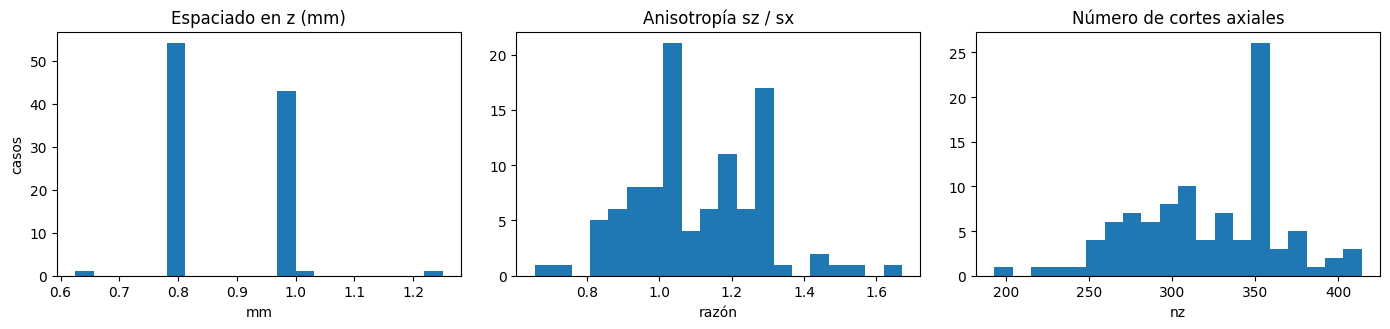

Casos elegidos para la ida y vuelta (menor, mediana y mayor sz/sx): ['039', '058', '047']


In [2]:
reader = sitk.ImageFileReader()
def _header(path):
    reader.SetFileName(str(resolve_repo_path(path)))
    reader.ReadImageInformation()
    return {"size": reader.GetSize(), "spacing": reader.GetSpacing(),
            "origin": reader.GetOrigin(), "direction": reader.GetDirection()}

rows = []
for r in df.itertuples(index=False):
    hi, hl = _header(r.image_path), _header(r.label_path)
    nx, ny, nz = hl["size"]; sx, sy, sz = hl["spacing"]
    rows.append({
        "case_id": r.case_id, "nx": nx, "ny": ny, "nz": nz,
        "sx": round(sx, 5), "sy": round(sy, 5), "sz": round(sz, 5),
        "ratio_z_x": sz / sx, "ratio_y_x": sy / sx,
        "ext_x_mm": nx * sx, "ext_y_mm": ny * sy, "ext_z_mm": nz * sz,
        "direccion_identidad": bool(np.allclose(hl["direction"], np.eye(3).ravel())),
        "cabecera_img_eq_lab": bool(hi["size"] == hl["size"]
                                    and np.allclose(hi["spacing"], hl["spacing"])
                                    and np.allclose(hi["origin"], hl["origin"])
                                    and np.allclose(hi["direction"], hl["direction"])),
    })
audit = pd.DataFrame(rows)

print("Combinaciones de espaciado (sx, sy, sz) en mm:")
display(audit.groupby(["sx", "sy", "sz"]).size().rename("casos").reset_index().sort_values("casos", ascending=False))
print("Tamaños (nx, ny, nz):")
display(audit.groupby(["nx", "ny"]).nz.agg(["count", "min", "median", "max"]).rename(columns={"count": "casos"}))
print(f"Dirección = identidad en {int(audit.direccion_identidad.sum())}/{len(audit)} casos")
print(f"Cabecera de imagen = cabecera de etiqueta en {int(audit.cabecera_img_eq_lab.sum())}/{len(audit)} casos")
print(f"sy/sx entre {audit.ratio_y_x.min():.3f} y {audit.ratio_y_x.max():.3f}  (1.0 = píxel axial cuadrado)")
print(f"sz/sx entre {audit.ratio_z_x.min():.2f} y {audit.ratio_z_x.max():.2f}  (>1: coronal/sagital se ven aplastados sin remuestrear)")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
ax[0].hist(audit.sz, bins=20); ax[0].set(title="Espaciado en z (mm)", xlabel="mm", ylabel="casos")
ax[1].hist(audit.ratio_z_x, bins=20); ax[1].set(title="Anisotropía sz / sx", xlabel="razón")
ax[2].hist(audit.nz, bins=20); ax[2].set(title="Número de cortes axiales", xlabel="nz")
plt.tight_layout(); plt.show()

# casos de prueba: menor, mediana y mayor anisotropía en z
order = audit.sort_values("ratio_z_x").case_id.tolist()
CASES = list(dict.fromkeys([order[0], order[len(order) // 2], order[-1]]))
print("Casos elegidos para la ida y vuelta (menor, mediana y mayor sz/sx):", CASES)

## 2. Funciones de geometría
- Plano **axial**: `vol[z]` → (y, x). **Coronal**: `vol[:, y, :]` → (z, x). **Sagital**: `vol[:, :, x]` → (z, y).
- **Remuestreo** (solo coronal/sagital): se lleva cada corte a píxeles cuadrados de `sx` mm (el espaciado en el plano axial), con vecino más cercano para no inventar IDs. El axial se deja como está, igual que hoy.
- **Letterbox** y su inversión: las funciones del equipo (`letterbox_pair`, `restore_letterbox_label_mask`).

In [3]:
PLANES = ("axial", "coronal", "sagital")


def get_slice(vol, plane, idx):
    if plane == "axial":
        return vol[idx]              # (y, x)
    if plane == "coronal":
        return vol[:, idx, :]        # (z, x)
    if plane == "sagital":
        return vol[:, :, idx]        # (z, y)
    raise ValueError(plane)


def put_slice(vol, plane, idx, arr):
    if plane == "axial":
        vol[idx] = arr
    elif plane == "coronal":
        vol[:, idx, :] = arr
    elif plane == "sagital":
        vol[:, :, idx] = arr
    else:
        raise ValueError(plane)


def n_slices(shape_zyx, plane):
    return {"axial": shape_zyx[0], "coronal": shape_zyx[1], "sagital": shape_zyx[2]}[plane]


def plane_spacing(plane, spacing_xyz):
    sx, sy, sz = spacing_xyz        # SimpleITK: (x, y, z)
    return {"axial": (sy, sx), "coronal": (sz, sx), "sagital": (sz, sy)}[plane]   # (mm por fila, mm por columna)


def resize_label_nn(arr, rows, cols):
    img = Image.fromarray(np.ascontiguousarray(arr, dtype=np.int32))
    return np.asarray(img.resize((int(cols), int(rows)), Image.Resampling.NEAREST), dtype=np.int32)


def resize_image_bilinear(arr, rows, cols):
    img = Image.fromarray(np.ascontiguousarray(arr, dtype=np.float32))
    return np.asarray(img.resize((int(cols), int(rows)), Image.Resampling.BILINEAR), dtype=np.float32)


def resampled_shape(shape, row_mm, col_mm, target_mm):
    return (max(1, int(round(shape[0] * row_mm / target_mm))), max(1, int(round(shape[1] * col_mm / target_mm))))


def roundtrip_slice(arr, row_mm, col_mm, target_mm, out_size=OUT_SIZE, resample=True):
    # etiqueta 2D -> (remuestreo) -> letterbox 256 -> restaurar -> (deshacer remuestreo)
    if resample:
        rs = resize_label_nn(arr, *resampled_shape(arr.shape, row_mm, col_mm, target_mm))
    else:
        rs = np.asarray(arr, dtype=np.int32)
    _, lab256, tf = letterbox_pair(np.zeros(rs.shape, np.float32), rs, output_size=out_size)
    back_rs = restore_letterbox_label_mask(lab256, rs.shape, tf, output_size=out_size)
    back = resize_label_nn(back_rs, *arr.shape) if resample else np.asarray(back_rs, dtype=np.int32)
    return back, tf


def roundtrip_volume(L, spacing_xyz, plane, target_mm=None, out_size=OUT_SIZE):
    sx = spacing_xyz[0]
    target_mm = sx if target_mm is None else target_mm
    row_mm, col_mm = plane_spacing(plane, spacing_xyz)
    R = np.zeros_like(L)
    scales = []
    for idx in range(n_slices(L.shape, plane)):
        arr = get_slice(L, plane, idx)
        if not arr.any():
            continue
        back, tf = roundtrip_slice(arr, row_mm, col_mm, target_mm, out_size, resample=(plane != "axial"))
        put_slice(R, plane, idx, back)
        scales.append(tf["scale"])
    scale_med = float(np.median(scales)) if scales else float("nan")
    return R, {"cortes": len(scales), "escala_med": scale_med, "mm_por_px_256": target_mm / scale_med}


def semantic_from_instances(L):
    sem = np.zeros(L.shape, dtype=np.uint8)
    sem[(L >= 1) & (L <= 10)] = 1; sem[(L >= 11) & (L <= 20)] = 2; sem[(L >= 21) & (L <= 30)] = 3
    return sem


def compare_volumes(L, R, spacing_xyz):
    sx, sy, sz = spacing_xyz
    U = (L > 0) | (R > 0)
    zs, ys, xs = np.flatnonzero(U.any((1, 2))), np.flatnonzero(U.any((0, 2))), np.flatnonzero(U.any((0, 1)))
    box = (slice(zs[0], zs[-1] + 1), slice(ys[0], ys[-1] + 1), slice(xs[0], xs[-1] + 1))
    L, R = L[box], R[box]
    fg, fr = L > 0, R > 0
    out = {"acuerdo_vox_fg": float((R[fg] == L[fg]).mean()),
           "dice_fg": float(2 * (fg & fr).sum() / (fg.sum() + fr.sum()))}
    sl, sr = semantic_from_instances(L), semantic_from_instances(R)
    for c in (1, 2, 3):
        a, b = sl == c, sr == c
        out[f"dice_region{c}"] = float(2 * (a & b).sum() / (a.sum() + b.sum())) if a.any() else float("nan")
    ids = [int(i) for i in np.unique(L) if i != 0]
    ious, shifts, verr, lost = [], [], [], 0
    mm = np.array([sz, sy, sx])
    for i in ids:
        a, b = L == i, R == i
        ious.append(float((a & b).sum() / (a | b).sum()))
        if not b.any():
            lost += 1
            continue
        shifts.append(float(np.linalg.norm((np.argwhere(a).mean(0) - np.argwhere(b).mean(0)) * mm)))
        verr.append(float((b.sum() - a.sum()) / a.sum() * 100))
    out.update({"n_fragmentos": len(ids), "fragmentos_perdidos": lost,
                "iou_frag_medio": float(np.mean(ious)), "iou_frag_min": float(np.min(ious)),
                "frag_iou_lt_05": int(np.sum(np.array(ious) < 0.5)),
                "desplaz_mediano_mm": float(np.median(shifts)) if shifts else float("nan"),
                "desplaz_max_mm": float(np.max(shifts)) if shifts else float("nan"),
                "err_volumen_mediano_%": float(np.median(verr)) if verr else float("nan")})
    return out

In [9]:
# ===== A. Auditoria de orientacion de los 100 casos (lee las etiquetas; ~1-2 min) =====
# Convencion SimpleITK: fisico = origen + D @ (espaciado * indice_xyz), en coordenadas LPS
# (+x = izquierda del paciente, +y = posterior, +z = superior). Identidad => ejes del array = L, P, S.

def axis_map(direction):
    """Letra fisica (LPS) hacia la que crece cada eje del array (x, y, z). Identidad -> 'LPS'."""
    D = np.asarray(direction, dtype=float).reshape(3, 3)       # columna k = eje k del array
    names = {(0, 1): "L", (0, -1): "R", (1, 1): "P", (1, -1): "A", (2, 1): "S", (2, -1): "I"}
    code, off_axis = "", 0.0
    for k in range(3):
        a = int(np.argmax(np.abs(D[:, k])))
        code += names[(a, 1 if D[a, k] > 0 else -1)]
        off_axis = max(off_axis, 1.0 - abs(D[a, k]))
    return code, off_axis


def is_axis_aligned(direction, tol=1e-3):
    D = np.asarray(direction, dtype=float).reshape(3, 3)
    return bool(np.all(1.0 - np.abs(D).max(0) < tol) and len(set(np.abs(D).argmax(0))) == 3)


def region_of(values):                      # ids 1-10 sacro, 11-20 coxal izq., 21-30 coxal der.
    return (np.asarray(values, dtype=np.int32) - 1) // 10 + 1


def _anatomy_flags(Q, reg):
    """Q: puntos (N,3) en el sistema a probar con ejes (x,y,z). Esperado en LPS: coxal izq. con x mayor que
    el der.; sacro mas posterior (y mayor) que los coxales; masa del sacro en la mitad superior (z mayor)."""
    if not all((reg == r).any() for r in (1, 2, 3)):
        return {"lr": np.nan, "ap": np.nan, "z": np.nan}
    c = {r: Q[reg == r].mean(0) for r in (1, 2, 3)}
    zs = Q[reg == 1][:, 2]
    return {"lr": bool(c[2][0] > c[3][0]),
            "ap": bool(c[1][1] > (c[2][1] + c[3][1]) / 2),
            "z": bool(zs.mean() > (zs.min() + zs.max()) / 2)}      # heuristico: la base del sacro es la parte ancha


def orientation_checks(L_zyx, spacing_xyz, origin_xyz, direction):
    zyx = np.argwhere(L_zyx > 0)
    reg = region_of(L_zyx[tuple(zyx.T)])
    xyz = zyx[:, ::-1].astype(float)
    D = np.asarray(direction, dtype=float).reshape(3, 3)
    P = np.asarray(origin_xyz) + (xyz * np.asarray(spacing_xyz)) @ D.T
    arr, fis = _anatomy_flags(xyz, reg), _anatomy_flags(P, reg)
    return ({f"{k}_array": v for k, v in arr.items()} | {f"{k}_fis": v for k, v in fis.items()}), int(len(zyx))


def audit_orientation(df):
    rows = []
    for i, r in enumerate(df.itertuples(index=False)):
        img = sitk.ReadImage(str(resolve_repo_path(r.label_path)))
        L = sitk.GetArrayFromImage(img)
        direction, spacing, origin = img.GetDirection(), img.GetSpacing(), img.GetOrigin()
        code, off_axis = axis_map(direction)
        flags, n_fg = orientation_checks(L, spacing, origin, direction)
        rows.append({"case_id": r.case_id, "codigo_ejes": code, "alineado_a_ejes": is_axis_aligned(direction),
                     "desv_oblicuidad": round(off_axis, 4), "identidad": bool(np.allclose(direction, np.eye(3).ravel(), atol=1e-4)),
                     "n_fg": n_fg, **flags})
    return pd.DataFrame(rows)


t0 = time.perf_counter()
orient = audit_orientation(df)
print(f"Auditoria lista en {time.perf_counter() - t0:.0f} s")

_flag_cols = [f"{k}_{s}" for k in ("lr", "ap", "z") for s in ("array", "fis")]
orient[_flag_cols] = orient[_flag_cols].astype(float)          # bool/NaN -> 1.0/0.0/NaN para poder sumar
orient["array_ok"] = orient[["lr_array", "ap_array", "z_array"]].astype(float).eq(1).all(axis=1)
orient["fis_ok"] = orient[["lr_fis", "ap_fis", "z_fis"]].astype(float).eq(1).all(axis=1)
summary = (orient.groupby("codigo_ejes")
           .agg(casos=("case_id", "size"), identidad=("identidad", "all"), alineado=("alineado_a_ejes", "all"),
                desv_max=("desv_oblicuidad", "max"),
                lr_array=("lr_array", "sum"), ap_array=("ap_array", "sum"), z_array=("z_array", "sum"),
                lr_fis=("lr_fis", "sum"), ap_fis=("ap_fis", "sum"), z_fis=("z_fis", "sum"))
           .sort_values("casos", ascending=False))
print("\nPor orientacion de los ejes del array (LPS = identidad). Columnas lr/ap/z = casos que cumplen la anatomia esperada:")
display(summary)

n = len(orient)
print(f"\nNo alineados a los ejes (oblicuos): {int((~orient.alineado_a_ejes).sum())}/{n}")
print(f"Anatomia coherente TAL CUAL se carga el array (lo que ve hoy la red): {int(orient.array_ok.sum())}/{n}")
print(f"Anatomia coherente segun la CABECERA (direccion):                    {int(orient.fis_ok.sum())}/{n}")
print(f"Casos donde la cabecera arregla lo que el array tiene mal:            "
      f"{int((~orient.array_ok & orient.fis_ok).sum())}")
print(f"Casos donde ni cabecera ni array son coherentes (revisar a mano):     "
      f"{int((~orient.array_ok & ~orient.fis_ok).sum())}")
bad = orient[~orient.fis_ok]
if len(bad):
    print("   ->", bad.case_id.tolist()[:20])

orient.to_csv(ROOT / "evidencias" / "orientacion_casos.csv", index=False)
print("Guardado: evidencias/orientacion_casos.csv")

Auditoria lista en 71 s

Por orientacion de los ejes del array (LPS = identidad). Columnas lr/ap/z = casos que cumplen la anatomia esperada:


,casos,identidad,alineado,desv_max,lr_array,ap_array,z_array,lr_fis,ap_fis,z_fis
codigo_ejes,,,,,,,,,,
LPS,66,True,True,0.0,66.0,66.0,66.0,66.0,66.0,66.0
RAS,34,False,True,0.0,0.0,0.0,34.0,34.0,34.0,34.0



No alineados a los ejes (oblicuos): 0/100
Anatomia coherente TAL CUAL se carga el array (lo que ve hoy la red): 66/100
Anatomia coherente segun la CABECERA (direccion):                    100/100
Casos donde la cabecera arregla lo que el array tiene mal:            34
Casos donde ni cabecera ni array son coherentes (revisar a mano):     0
Guardado: evidencias/orientacion_casos.csv


Verificando 34 casos con direccion distinta de la identidad...
Vóxeles de etiqueta conservados: 34/34
Anatomia coherente tras canonizar: 34/34


,case_id,codigo_antes,n_fg_igual,array_ok_despues,fis_ok_despues


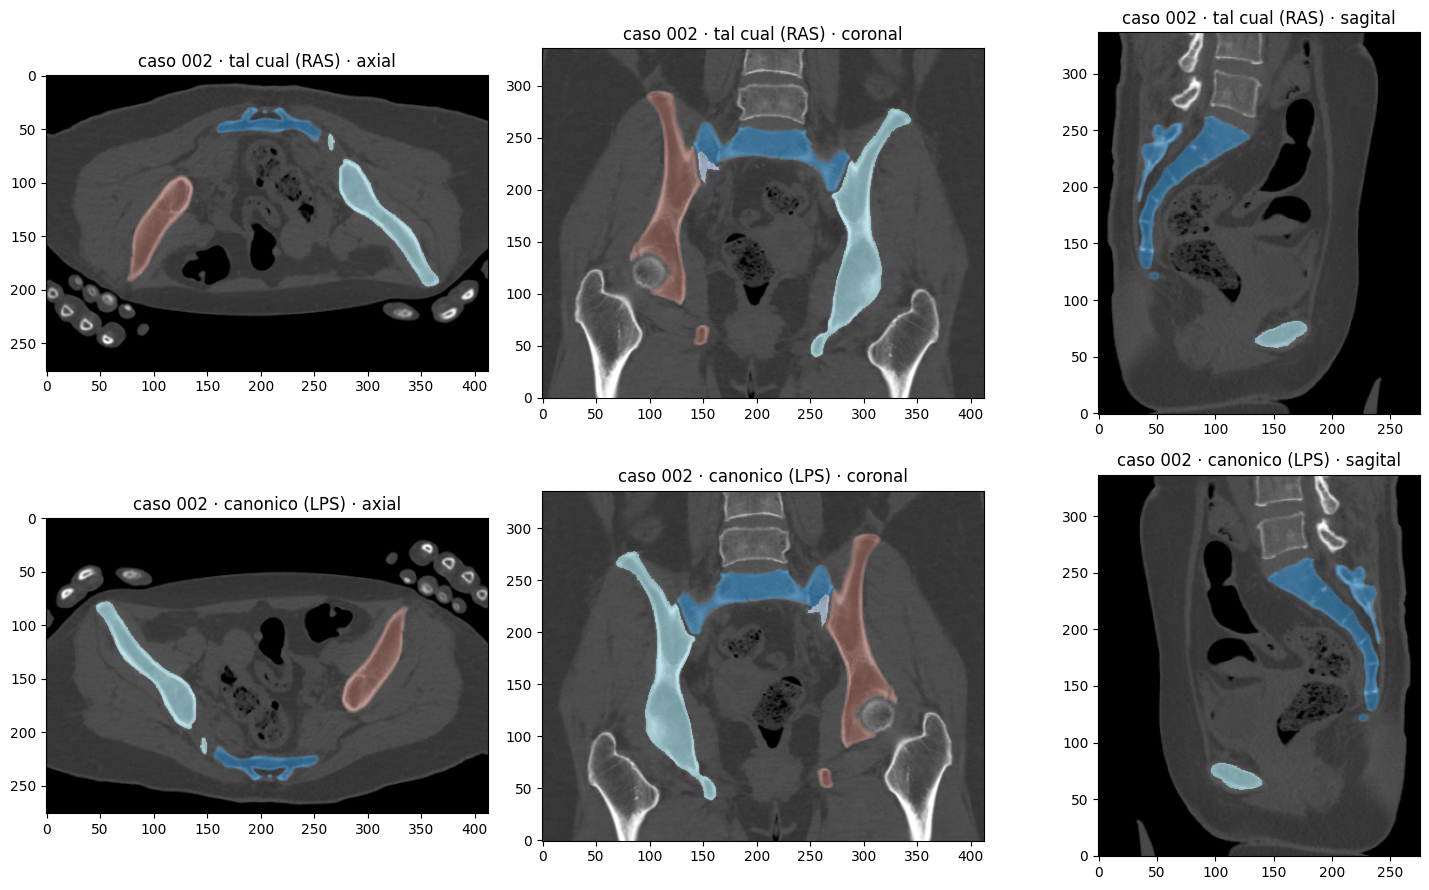

In [10]:
# ===== B. Cargador canonico (ejes del array = L, P, S) + verificacion + vista antes/despues =====
def canonicalize_zyx(arr_zyx, spacing_xyz, origin_xyz, direction):
    """Permuta/voltea los ejes para que x->izquierda, y->posterior, z->superior (direccion = identidad).
    Solo para direcciones alineadas a los ejes (permutacion con signo); no interpola, no cambia ningun valor."""
    D = np.asarray(direction, dtype=float).reshape(3, 3)
    if not is_axis_aligned(D):
        raise NotImplementedError(f"Direccion oblicua (desviacion {axis_map(D)[1]:.3f}); hay que remuestrear.")
    sp, org = np.asarray(spacing_xyz, dtype=float), np.asarray(origin_xyz, dtype=float)
    rows = np.abs(D).argmax(0)                               # eje fisico (0=L,1=P,2=S) de cada eje k del array
    signs = np.sign(D[rows, np.arange(3)])
    k_of = [int(np.where(rows == p)[0][0]) for p in range(3)]    # eje del array que pasa a ser el fisico p
    a = np.transpose(arr_zyx, (2, 1, 0))                     # ejes (x, y, z) del array
    out = np.transpose(a, k_of)
    for p in range(3):
        if signs[k_of[p]] < 0:
            out = np.flip(out, axis=p)
    idx0 = np.array([a.shape[k] - 1 if signs[k] < 0 else 0 for k in range(3)], dtype=float)
    new_origin = org + D @ (sp * idx0)
    return np.ascontiguousarray(np.transpose(out, (2, 1, 0))), tuple(sp[k_of]), tuple(new_origin)


def load_canonical(path, is_label):
    """Lee un .mha y lo devuelve en orientacion canonica: (array (z,y,x), espaciado (x,y,z), origen (x,y,z))."""
    img = sitk.ReadImage(str(resolve_repo_path(path)))
    arr = sitk.GetArrayFromImage(img).astype(np.int16 if is_label else np.float32)
    direction = img.GetDirection()
    if np.allclose(direction, np.eye(3).ravel(), atol=1e-4):
        return arr, tuple(img.GetSpacing()), tuple(img.GetOrigin())
    return canonicalize_zyx(arr, img.GetSpacing(), img.GetOrigin(), direction)


# --- verificacion: los casos con direccion distinta de la identidad, tras canonizar ---
todo = orient[~orient.identidad]
print(f"Verificando {len(todo)} casos con direccion distinta de la identidad...")
ver = []
for r in todo.itertuples(index=False):
    row = df[df.case_id == r.case_id].iloc[0]
    L, sp, org = load_canonical(row.label_path, is_label=True)
    flags, n_fg = orientation_checks(L, sp, org, np.eye(3).ravel())
    ver.append({"case_id": r.case_id, "codigo_antes": r.codigo_ejes, "n_fg_igual": n_fg == r.n_fg,
                "array_ok_despues": all(flags[f"{k}_array"] is True for k in ("lr", "ap", "z")),
                "fis_ok_despues": all(flags[f"{k}_fis"] is True for k in ("lr", "ap", "z"))})
ver = pd.DataFrame(ver)
if len(ver):
    print(f"Vóxeles de etiqueta conservados: {int(ver.n_fg_igual.sum())}/{len(ver)}")
    print(f"Anatomia coherente tras canonizar: {int(ver.array_ok_despues.sum())}/{len(ver)}")
    display(ver[~(ver.n_fg_igual & ver.array_ok_despues)])

# --- vista antes / despues de un caso representativo ---
ejemplos = orient[~orient.identidad & ~orient.array_ok]
ejemplo = (ejemplos if len(ejemplos) else todo).case_id.iloc[0] if len(todo) else None
if ejemplo is not None:
    row = df[df.case_id == ejemplo].iloc[0]
    raw = sitk.ReadImage(str(resolve_repo_path(row.image_path)))
    raw_vol = sitk.GetArrayFromImage(raw).astype(np.float32)
    raw_lab = sitk.GetArrayFromImage(sitk.ReadImage(str(resolve_repo_path(row.label_path)))).astype(np.int16)
    can_vol, can_sp, _ = load_canonical(row.image_path, is_label=False)
    can_lab, _, _ = load_canonical(row.label_path, is_label=True)
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    for i, (name, v, l, sp) in enumerate((("tal cual (" + axis_map(raw.GetDirection())[0] + ")", raw_vol, raw_lab, raw.GetSpacing()),
                                           ("canonico (LPS)", can_vol, can_lab, can_sp))):
        zc, yc, xc = [int(round(c)) for c in np.argwhere(l > 0).mean(0)]
        w = apply_hu_window(v)
        for j, (plane, idx) in enumerate((("axial", zc), ("coronal", yc), ("sagital", xc))):
            rm, cm = plane_spacing(plane, sp)
            img, lb = get_slice(w, plane, idx), get_slice(l, plane, idx)
            org = "upper" if plane == "axial" else "lower"
            axes[i, j].imshow(img, cmap="gray", vmin=0, vmax=1, aspect=rm / cm, origin=org)
            axes[i, j].imshow(np.ma.masked_where(lb == 0, lb), cmap="tab20", alpha=0.6, aspect=rm / cm, origin=org, interpolation="nearest")
            axes[i, j].set_title(f"caso {ejemplo} · {name} · {plane}")
    plt.tight_layout(); plt.show()

In [12]:
# ===== C. ¿Mide algo la comprobacion de distancias? (casos con fragmentos separados) =====
from src.distancias_fragmentos import measure_fragment_separations

cand = df.sort_values("n_fragments", ascending=False).case_id.head(8).tolist() if "n_fragments" in df.columns else list(CASES)
rows, tables = [], {}
for case in cand:
    r = df[df.case_id == case].iloc[0]
    L, sp, _ = load_canonical(r.label_path, is_label=True)
    t0 = time.perf_counter()
    tab = measure_fragment_separations(L, sp, case_id=case)
    tables[case] = tab
    nm = tab[~tab.is_main]
    d = nm.distance_mm.astype(float)
    rows.append({"case_id": case, "fragmentos_no_principales": len(nm), "dist_min_mm": d.min(), "dist_mediana_mm": d.median(),
                 "dist_max_mm": d.max(), "con_dist_0": int((d <= 0).sum()), "tiempo_s": round(time.perf_counter() - t0, 1)})
dist_scan = pd.DataFrame(rows)
display(dist_scan.round(2))
first = cand[0]
print("Columnas que devuelve measure_fragment_separations:", list(tables[first].columns))
print(f"Tabla completa del caso {first}:")
display(tables[first].round(2))

best = dist_scan.sort_values("dist_max_mm", ascending=False).case_id.iloc[0]
DIST_CASE_OVERRIDE = best
print(f"\nCaso con mayor separacion: {best}  -> DIST_CASE_OVERRIDE = '{best}' (lo usa la celda de ida y vuelta, ver reemplazo)")

,case_id,fragmentos_no_principales,dist_min_mm,dist_mediana_mm,dist_max_mm,con_dist_0,tiempo_s
0,024,6,0.0,0.0,19.08,4,5.4
1,039,6,0.0,0.0,33.36,5,1.6
2,031,5,0.0,0.0,1.49,4,3.9
3,025,5,0.0,0.0,1.85,4,2.9
4,084,5,0.0,0.0,11.56,3,3.5
5,085,5,0.0,0.0,49.37,3,2.8
6,049,5,0.0,0.0,5.27,4,5.5
7,087,5,0.0,0.0,5.39,4,4.1


Columnas que devuelve measure_fragment_separations: ['case_id', 'region', 'fragment_id', 'main_fragment_id', 'is_main', 'n_voxels', 'distance_mm']
Tabla completa del caso 024:


,case_id,region,fragment_id,main_fragment_id,is_main,n_voxels,distance_mm
0,024,coxal_derecho,21,21,True,555108,0.00
1,024,coxal_derecho,22,21,False,21769,0.00
2,024,coxal_derecho,23,21,False,16174,0.00
3,024,coxal_izquierdo,11,11,True,543290,0.00
4,024,coxal_izquierdo,12,11,False,39630,0.00
5,024,coxal_izquierdo,13,11,False,2681,19.08
6,024,coxal_izquierdo,14,11,False,3272,3.35
7,024,sacro,1,1,True,346528,0.00
8,024,sacro,2,1,False,77090,0.00



Caso con mayor separacion: 085  -> DIST_CASE_OVERRIDE = '085' (lo usa la celda de ida y vuelta, ver reemplazo)


### Prueba 0 — volumen sintético (comprueba el código, no los datos)
Un volumen anisotrópico con bloques asimétricos y un fragmento pequeño pegado. Debe recuperarse casi igual en los tres planos. Si esta celda falla, el problema está en las funciones, no en tus datos.

In [4]:
synthetic = np.zeros((90, 128, 160), dtype=np.int16)            # (z, y, x)
synthetic[20:70, 40:90, 70:90] = 1                              # "sacro"
synthetic[25:75, 30:100, 20:60] = 11                            # "coxal izquierdo"
synthetic[40:50, 60:70, 62:68] = 12                             # fragmento pequeño pegado
synthetic[25:75, 30:100, 100:140] = 21                          # "coxal derecho"
synthetic_spacing = (0.8, 0.8, 1.6)                             # (x, y, z) mm

for plane in PLANES:
    R, info = roundtrip_volume(synthetic, synthetic_spacing, plane)
    m = compare_volumes(synthetic, R, synthetic_spacing)
    print(f"{plane:8s} dice_fg={m['dice_fg']:.3f}  acuerdo_vox={m['acuerdo_vox_fg']:.3f}  "
          f"iou_frag_min={m['iou_frag_min']:.2f}  desplaz_med={m['desplaz_mediano_mm']:.2f} mm  perdidos={m['fragmentos_perdidos']}")
    assert m["dice_fg"] > 0.9 and m["fragmentos_perdidos"] == 0, (plane, m)
print("Prueba 0 OK: ida y vuelta consistente en los tres planos")

axial    dice_fg=1.000  acuerdo_vox=1.000  iou_frag_min=1.00  desplaz_med=0.00 mm  perdidos=0
coronal  dice_fg=1.000  acuerdo_vox=1.000  iou_frag_min=1.00  desplaz_med=0.00 mm  perdidos=0
sagital  dice_fg=1.000  acuerdo_vox=1.000  iou_frag_min=1.00  desplaz_med=0.00 mm  perdidos=0
Prueba 0 OK: ida y vuelta consistente en los tres planos


## 3. Cómo se ven los tres planos (un caso real)
Arriba: cortes crudos dibujados con su **proporción física real** (usando el espaciado). Abajo: tras remuestreo y letterbox a 256×256, que es lo que vería la red. Se asume que `z` crece hacia la cabeza (`origin="lower"` en coronal/sagital); si la pelvis sale al revés es solo el orden de `z` del archivo y no afecta a la prueba.

Caso 058 | espaciado (x,y,z) = (np.float64(0.941), np.float64(0.941), np.float64(1.0)) mm | forma (z,y,x) = (311, 287, 437)
Cortes que pasan por el centro de las etiquetas: z=195, y=157, x=206


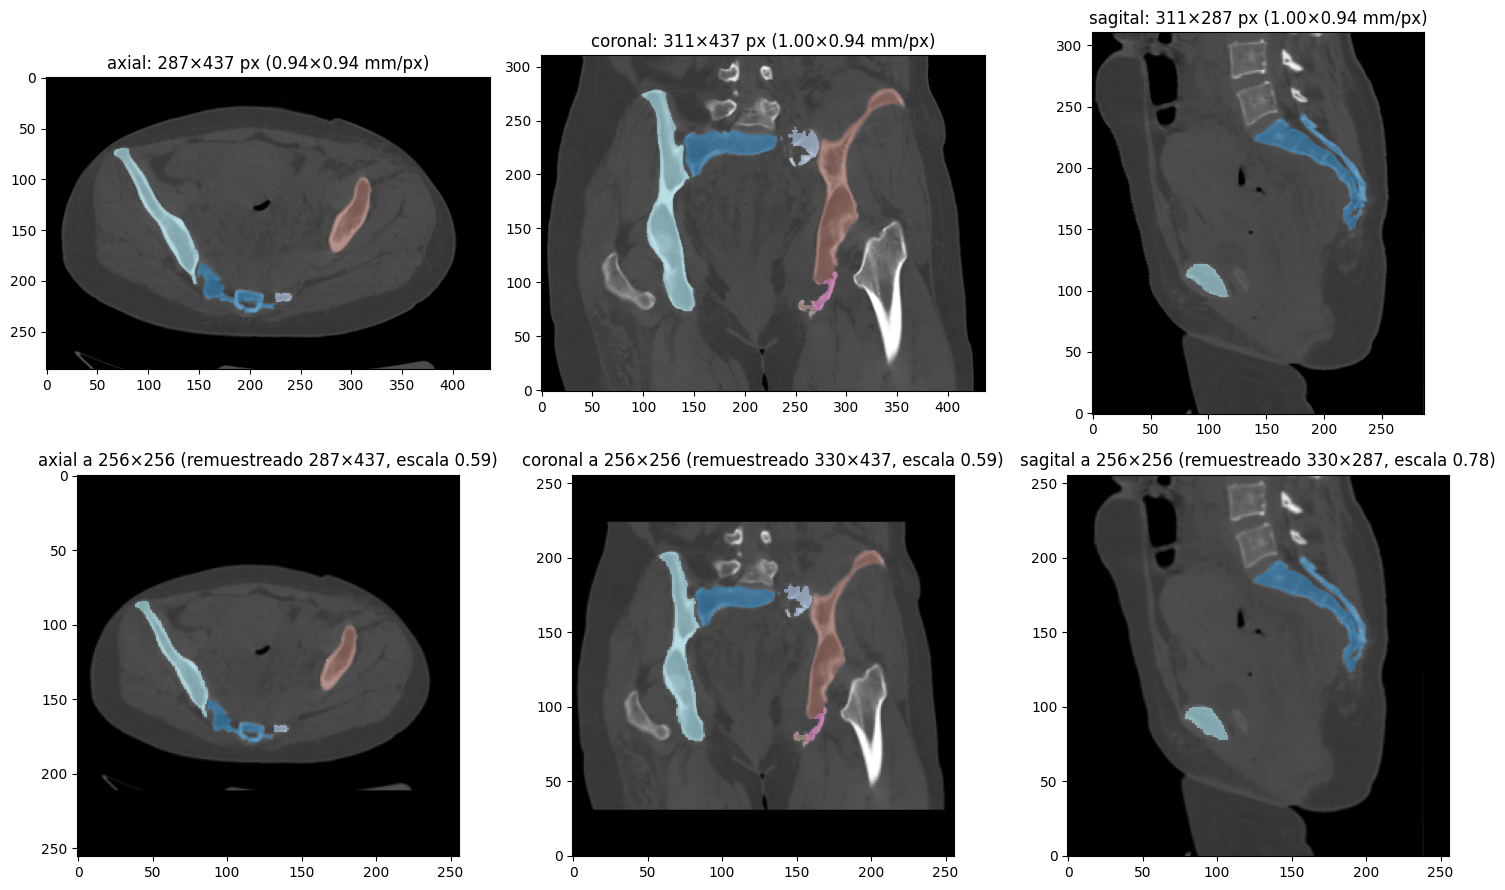

In [13]:
case = CASES[len(CASES) // 2]
row = df[df.case_id == case].iloc[0]
vol, spacing, _ = load_canonical(row.image_path, is_label=False)
win = apply_hu_window(vol)
lab, _, _ = load_canonical(row.label_path, is_label=True)
zc, yc, xc = [int(round(v)) for v in np.argwhere(lab > 0).mean(0)]
print(f"Caso {case} | espaciado (x,y,z) = {tuple(round(s, 3) for s in spacing)} mm | forma (z,y,x) = {lab.shape}")
print(f"Cortes que pasan por el centro de las etiquetas: z={zc}, y={yc}, x={xc}")

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for j, (plane, idx) in enumerate((("axial", zc), ("coronal", yc), ("sagital", xc))):
    img, lb = get_slice(win, plane, idx), get_slice(lab, plane, idx)
    row_mm, col_mm = plane_spacing(plane, spacing)
    origin = "upper" if plane == "axial" else "lower"
    ov = np.ma.masked_where(lb == 0, lb)
    axes[0, j].imshow(img, cmap="gray", vmin=0, vmax=1, aspect=row_mm / col_mm, origin=origin)
    axes[0, j].imshow(ov, cmap="tab20", alpha=0.6, aspect=row_mm / col_mm, origin=origin, interpolation="nearest")
    axes[0, j].set_title(f"{plane}: {img.shape[0]}×{img.shape[1]} px ({row_mm:.2f}×{col_mm:.2f} mm/px)")

    if plane == "axial":
        img_rs, lb_rs = img, lb
    else:
        shp = resampled_shape(img.shape, row_mm, col_mm, spacing[0])
        img_rs, lb_rs = resize_image_bilinear(img, *shp), resize_label_nn(lb, *shp)
    img256, lb256, tf = letterbox_pair(img_rs, lb_rs, output_size=OUT_SIZE)
    axes[1, j].imshow(img256, cmap="gray", vmin=0, vmax=1, origin=origin)
    axes[1, j].imshow(np.ma.masked_where(lb256 == 0, lb256), cmap="tab20", alpha=0.6, origin=origin, interpolation="nearest")
    axes[1, j].set_title(f"{plane} a 256×256 (remuestreado {img_rs.shape[0]}×{img_rs.shape[1]}, escala {tf['scale']:.2f})")
plt.tight_layout(); plt.show()

## 4. Ida y vuelta con las etiquetas reales
Para cada caso y plano: cortar → remuestrear (coronal/sagital) → letterbox 256 → restaurar → reapilar, y comparar con el volumen original.

Métricas (todas sobre las etiquetas de instancia):
- `dice_fg` / `acuerdo_vox_fg`: coincidencia global de vóxeles de hueso.
- `iou_frag_*`, `fragmentos_perdidos`, `frag_iou_lt_05`: qué pasa con cada fragmento (los pequeños son los más expuestos).
- `desplaz_*_mm`: cuánto se mueve el centroide de cada fragmento, **en milímetros** (usa el espaciado real).
- `mm_por_px_256`: tamaño de un píxel de 256×256 en mm; un desplazamiento menor que ~1 píxel es esperable.

In [14]:
RESTORED = {}                       # solo se guarda el caso de la comprobación de distancias (memoria)
DIST_CASE = globals().get("DIST_CASE_OVERRIDE", CASES[len(CASES) // 2])
CASES = list(dict.fromkeys(CASES + [DIST_CASE]))
results = []
for case in CASES:
    r = df[df.case_id == case].iloc[0]
    L, spacing, _ = load_canonical(r.label_path, is_label=True)
    for plane in PLANES:
        t0 = time.perf_counter()
        R, info = roundtrip_volume(L, spacing, plane)
        m = compare_volumes(L, R, spacing)
        results.append({"case_id": case, "plano": plane, **info, **m, "tiempo_s": time.perf_counter() - t0})
        if case == DIST_CASE:
            RESTORED[plane] = (L if plane == "axial" else RESTORED["axial"][0], R, spacing)
        print(f"[{case}] {plane:8s} dice_fg={m['dice_fg']:.3f} | iou_frag_min={m['iou_frag_min']:.2f} | "
              f"perdidos={m['fragmentos_perdidos']}/{m['n_fragmentos']} | desplaz_med={m['desplaz_mediano_mm']:.2f} mm | {results[-1]['tiempo_s']:.0f} s")

results = pd.DataFrame(results)
results["desplaz_en_px"] = results["desplaz_mediano_mm"] / results["mm_por_px_256"]
base = results[results.plano == "axial"].set_index("case_id")["dice_fg"]
results["vs_axial_dice"] = results.apply(lambda r: r.dice_fg - base[r.case_id], axis=1)
results["revisar"] = (results.plano != "axial") & ((results.vs_axial_dice < -0.03) | (results.desplaz_en_px > 1.0) | (results.fragmentos_perdidos > 0))
cols = ["case_id", "plano", "cortes", "escala_med", "mm_por_px_256", "dice_fg", "acuerdo_vox_fg", "dice_region1", "dice_region2",
        "dice_region3", "n_fragmentos", "fragmentos_perdidos", "frag_iou_lt_05", "iou_frag_medio", "iou_frag_min",
        "desplaz_mediano_mm", "desplaz_en_px", "desplaz_max_mm", "err_volumen_mediano_%", "vs_axial_dice", "revisar"]
display(results[cols].round(3))
results.to_csv(ROOT / "evidencias" / "ida_y_vuelta_planos.csv", index=False)
print("Guardado: evidencias/ida_y_vuelta_planos.csv")

[039] axial    dice_fg=0.975 | iou_frag_min=0.89 | perdidos=0/9 | desplaz_med=0.29 mm | 1 s
[039] coronal  dice_fg=0.969 | iou_frag_min=0.81 | perdidos=0/9 | desplaz_med=0.29 mm | 1 s
[039] sagital  dice_fg=0.987 | iou_frag_min=0.89 | perdidos=0/9 | desplaz_med=0.11 mm | 2 s
[058] axial    dice_fg=0.959 | iou_frag_min=0.81 | perdidos=0/6 | desplaz_med=0.13 mm | 2 s
[058] coronal  dice_fg=0.962 | iou_frag_min=0.80 | perdidos=0/6 | desplaz_med=0.13 mm | 2 s
[058] sagital  dice_fg=0.979 | iou_frag_min=0.90 | perdidos=0/6 | desplaz_med=0.11 mm | 3 s
[047] axial    dice_fg=0.964 | iou_frag_min=0.89 | perdidos=0/5 | desplaz_med=0.53 mm | 2 s
[047] coronal  dice_fg=0.965 | iou_frag_min=0.85 | perdidos=0/5 | desplaz_med=0.48 mm | 2 s
[047] sagital  dice_fg=0.965 | iou_frag_min=0.85 | perdidos=0/5 | desplaz_med=0.55 mm | 3 s
[085] axial    dice_fg=0.966 | iou_frag_min=0.83 | perdidos=0/8 | desplaz_med=0.12 mm | 2 s
[085] coronal  dice_fg=0.968 | iou_frag_min=0.80 | perdidos=0/8 | desplaz_med=0.

,case_id,plano,cortes,escala_med,mm_por_px_256,dice_fg,acuerdo_vox_fg,dice_region1,dice_region2,dice_region3,...,fragmentos_perdidos,frag_iou_lt_05,iou_frag_medio,iou_frag_min,desplaz_mediano_mm,desplaz_en_px,desplaz_max_mm,err_volumen_mediano_%,vs_axial_dice,revisar
0,039,axial,265,0.795,1.535,0.975,0.973,0.975,0.975,0.975,...,0,0,0.935,0.887,0.295,0.192,0.537,0.012,0.000,False
1,039,coronal,124,0.795,1.535,0.969,0.965,0.964,0.968,0.972,...,0,0,0.903,0.806,0.287,0.187,0.575,-0.556,-0.006,False
2,039,sagital,251,0.996,1.225,0.987,0.986,0.983,0.987,0.989,...,0,0,0.955,0.888,0.114,0.093,0.284,0.225,0.012,False
3,058,axial,225,0.586,1.607,0.959,0.959,0.958,0.959,0.961,...,0,0,0.894,0.806,0.131,0.081,0.512,0.256,0.000,False
4,058,coronal,169,0.586,1.607,0.962,0.961,0.958,0.962,0.964,...,0,0,0.894,0.802,0.128,0.080,0.727,-0.024,0.002,False
5,058,sagital,314,0.776,1.214,0.979,0.979,0.974,0.980,0.982,...,0,0,0.943,0.903,0.110,0.091,0.169,0.244,0.020,False
6,047,axial,165,0.500,1.496,0.964,0.964,0.961,0.962,0.968,...,0,0,0.921,0.887,0.533,0.356,0.552,0.021,0.000,False
7,047,coronal,201,0.500,1.496,0.965,0.964,0.962,0.966,0.967,...,0,0,0.912,0.848,0.479,0.320,0.629,-0.271,0.001,False
8,047,sagital,379,0.500,1.496,0.965,0.963,0.954,0.969,0.970,...,0,0,0.913,0.852,0.546,0.365,0.633,-0.284,0.001,False
9,085,axial,275,0.620,1.475,0.966,0.963,0.965,0.965,0.967,...,0,0,0.911,0.831,0.125,0.085,0.262,-0.365,0.000,False


Guardado: evidencias/ida_y_vuelta_planos.csv


## 5. (Opcional) Efecto en las distancias de separación, en mm
La medición de separación (src/distancias_fragmentos.py) debe hacerse sobre máscaras en la geometría original. Aquí se calcula sobre el volumen restaurado de cada plano y se compara con la referencia sobre las etiquetas originales. Los fragmentos pegados al principal tienen distancias de ~1 vóxel (≈0.8 mm), por debajo de lo que resuelve un píxel de 256×256, así que esta tabla indica cuánto se distorsionan.

In [15]:
RUN_DISTANCE_CHECK = True
try:
    from src.distancias_fragmentos import measure_fragment_separations
except Exception as exc:
    print("No se pudo importar distancias_fragmentos:", exc)
    RUN_DISTANCE_CHECK = False

if RUN_DISTANCE_CHECK:
    L0, _, spacing0 = RESTORED["axial"]
    ref = measure_fragment_separations(L0, spacing0, case_id=DIST_CASE)
    ref = ref[~ref.is_main][["region", "fragment_id", "distance_mm"]].rename(columns={"distance_mm": "ref_mm"})
    summary, detail = [], ref.copy()
    for plane in PLANES:
        _, R, sp = RESTORED[plane]
        got = measure_fragment_separations(R, sp, case_id=DIST_CASE)
        got = got[~got.is_main][["region", "fragment_id", "distance_mm"]].rename(columns={"distance_mm": f"{plane}_mm"})
        detail = detail.merge(got, on=["region", "fragment_id"], how="left")
        err = (detail[f"{plane}_mm"] - detail["ref_mm"]).abs()
        summary.append({"plano": plane, "fragmentos": len(detail), "sin_medida": int(detail[f"{plane}_mm"].isna().sum()),
                        "error_abs_mediano_mm": err.median(), "error_abs_max_mm": err.max()})
    print(f"Caso {DIST_CASE}: distancia al fragmento principal, original vs restaurado")
    display(detail.round(3))
    display(pd.DataFrame(summary).round(3))

Caso 085: distancia al fragmento principal, original vs restaurado


,region,fragment_id,ref_mm,axial_mm,coronal_mm,sagital_mm
0,coxal_derecho,22,0.000,0.000,0.000,0.000
1,coxal_izquierdo,12,49.370,48.864,48.628,49.448
2,coxal_izquierdo,13,0.000,0.000,0.000,0.000
3,coxal_izquierdo,14,0.000,0.000,0.000,0.000
4,sacro,2,6.142,6.074,5.987,5.786


,plano,fragmentos,sin_medida,error_abs_mediano_mm,error_abs_max_mm
0,axial,5,0,0.0,0.505
1,coronal,5,0,0.0,0.742
2,sagital,5,0,0.0,0.356


In [16]:
print(orient.merge(df[["case_id", "split"]], on="case_id").groupby(["split", "identidad"]).size().unstack(fill_value=0))

identidad  False  True 
split                  
test           8     12
train         22     53
val            4      1


## Cómo leer los resultados
- **Prueba 0** debe pasar. Si falla, hay un error en las funciones de geometría.
- **Axial** es la referencia: su pérdida es la de la tubería actual (letterbox a 256).
- **Coronal/sagital** no deberían ser claramente peores que el axial. La columna `revisar` marca: Dice 0.03 por debajo del axial, desplazamiento mayor a 1 píxel o algún fragmento perdido.
- **Fragmentos perdidos / IoU bajo:** los pequeños suelen sufrir en los tres planos al pasar a 256. Es información sobre el límite de resolución, no necesariamente un error.
- **Distancias:** si el error es del orden de 1–2 mm, confirma que la medición debe hacerse en la geometría original y no sobre máscaras de 256×256.
- **Auditoría:** mirar si hay casos con dirección distinta de la identidad o con cabeceras distintas entre imagen y etiqueta; son los que pueden dar problemas silenciosos.

**Para enviarme:** la tabla de auditoría (combinaciones de espaciado), la figura de los tres planos, la tabla de resultados (o `ida_y_vuelta_planos.csv`) y la tabla de distancias.

In [ ]:
# ===== ¿Sirve el centro del campo de visión (FOV) como linea media de la pelvis? (~1-2 min) =====
from src.orientacion import load_canonical

rows = []
for r in df.itertuples(index=False):
    L, sp, _ = load_canonical(r.label_path, is_label=True, resolver=resolve_repo_path)   # canonico: x crece hacia la izquierda
    zyx = np.argwhere(L > 0)
    x_mm = zyx[:, 2] * sp[0]
    reg = (L[tuple(zyx.T)].astype(int) - 1) // 10 + 1                                    # 1 sacro, 2 coxal izq., 3 coxal der.
    x_fov, x_sac = L.shape[2] * sp[0] / 2, x_mm[reg == 1].mean()
    izq, der = x_mm[reg == 2], x_mm[reg == 3]
    rows.append({"case_id": r.case_id,
                 "sacro_menos_centro_fov_mm": x_sac - x_fov,
                 "ancho_pelvis_mm": izq.mean() - der.mean(),
                 "coxal_bien_lado_con_fov": ((izq > x_fov).sum() + (der < x_fov).sum()) / (len(izq) + len(der)),
                 "coxal_bien_lado_con_sacro": ((izq > x_sac).sum() + (der < x_sac).sum()) / (len(izq) + len(der))})
mid = pd.DataFrame(rows)
display(mid.drop(columns="case_id").describe(percentiles=[.05, .5, .95]).round(3).T)
print("Casos con >5 % del coxal del lado equivocado usando el centro del FOV: ",
      int((mid.coxal_bien_lado_con_fov < 0.95).sum()), "/", len(mid))
print("Casos con >5 % del coxal del lado equivocado usando el centro del sacro:",
      int((mid.coxal_bien_lado_con_sacro < 0.95).sum()), "/", len(mid))
mid.to_csv(ROOT / "evidencias" / "linea_media.csv", index=False)